<a href="https://colab.research.google.com/github/MithravindaU/ecosphere-sim/blob/main/ecosphere_sim.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install numpy matplotlib

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import random
import time
from IPython.display import clear_output

world = np.zeros((20, 20))

In [ ]:

for i in range(50):

    x = np.random.randint(0, 20)

    y = np.random.randint(0, 20)

    world[x][y] = 1


In [ ]:
herbivores = []

for i in range(5):

    x = np.random.randint(0,20)

    y = np.random.randint(0,20)

    herbivores.append([x,y])

In [ ]:
for step in range(100):

  display_world = world.copy()

In [ ]:
for animal in herbivores:

  dx = random.choice(
    [-1, 0, 1]
)

dy = random.choice(
    [-1, 0, 1]
)
animal[0] += dx
animal[1] += dy

animal[0] = max(
    0,
    min(19, animal[0])
)

animal[1] = max(
    0,
    min(19, animal[1])
)
display_world[
            animal[0]
        ][
            animal[1]
        ] = 2

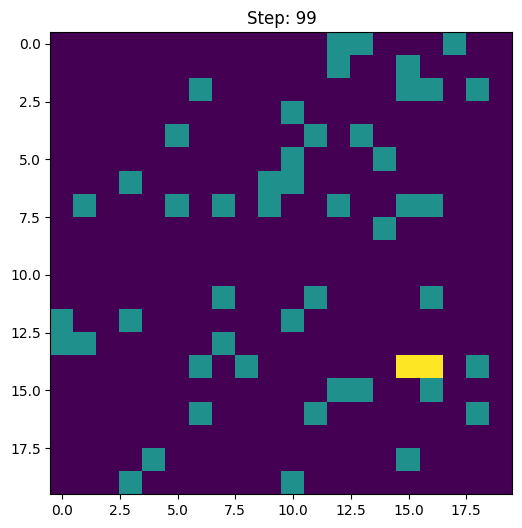

In [ ]:
clear_output(wait=True)

plt.figure(figsize=(6,6))

plt.imshow(display_world)

plt.title(
        f"Step: {step}"
    )

plt.show()


time.sleep(0.2)

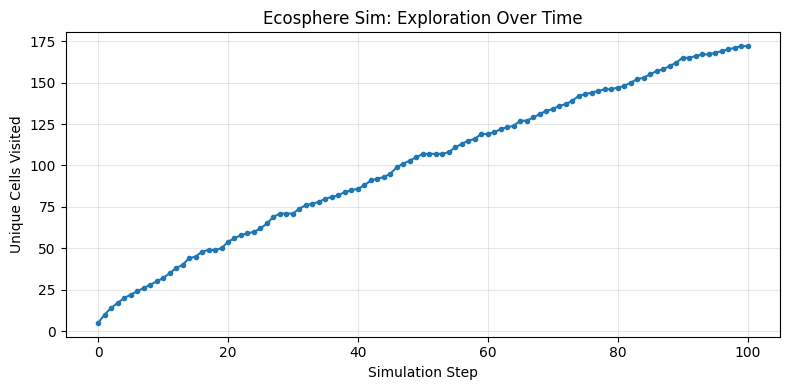

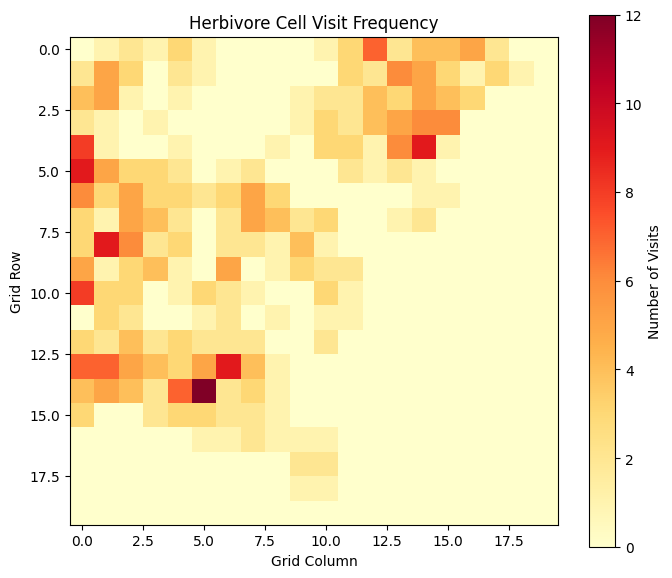

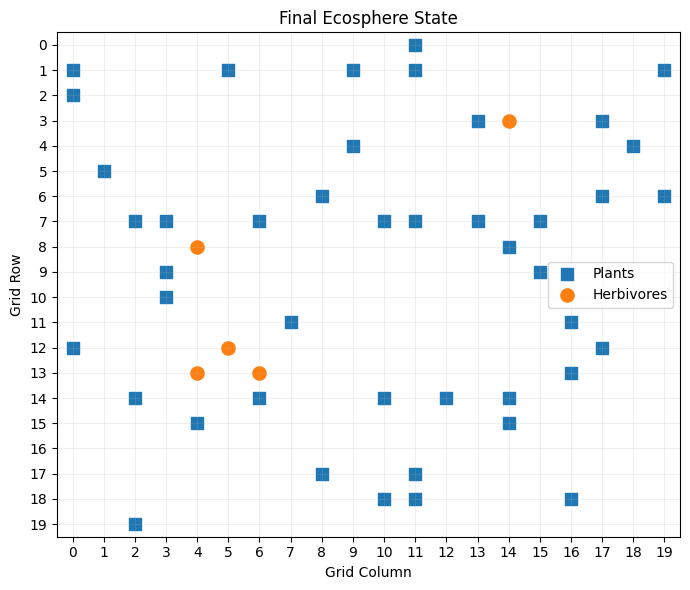

SIMULATION SUMMARY
------------------
Grid size: 20 x 20
Plants placed: 44
Herbivores: 5
Simulation steps: 100
Total movement actions: 500
Unique cells visited: 172
Grid coverage: 43.0 %
Saved: movement_over_time.png
Saved: visited_cells_heatmap.png
Saved: simulation_final.png


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import random

# Reproducible results
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Simulation settings
GRID_SIZE = 20
NUM_PLANTS = 50
NUM_HERBIVORES = 5
STEPS = 100

# 0 = empty, 1 = plant
world = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

# Place plants
for _ in range(NUM_PLANTS):
    x, y = np.random.randint(0, GRID_SIZE, size=2)
    world[x, y] = 1

# Place herbivores
herbivores = [
    list(np.random.randint(0, GRID_SIZE, size=2))
    for _ in range(NUM_HERBIVORES)
]

# Track movement statistics
visited_cells = np.zeros(
    (GRID_SIZE, GRID_SIZE), dtype=int
)
unique_cells_over_time = []
total_moves_over_time = []

for animal in herbivores:
    visited_cells[animal[0], animal[1]] += 1

unique_cells_over_time.append(
    np.count_nonzero(visited_cells)
)
total_moves = 0
total_moves_over_time.append(total_moves)

# Run simulation
for step in range(1, STEPS + 1):
    for animal in herbivores:
        dx = random.choice([-1, 0, 1])
        dy = random.choice([-1, 0, 1])

        # Keep agents inside the grid
        animal[0] = max(
            0, min(GRID_SIZE - 1, animal[0] + dx)
        )
        animal[1] = max(
            0, min(GRID_SIZE - 1, animal[1] + dy)
        )

        visited_cells[animal[0], animal[1]] += 1
        total_moves += 1

    unique_cells_over_time.append(
        np.count_nonzero(visited_cells)
    )
    total_moves_over_time.append(total_moves)

# Graph 1: Unique cells visited over time
plt.figure(figsize=(8, 4))
plt.plot(
    range(STEPS + 1),
    unique_cells_over_time,
    marker="."
)
plt.title("Ecosphere Sim: Exploration Over Time")
plt.xlabel("Simulation Step")
plt.ylabel("Unique Cells Visited")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("movement_over_time.png", dpi=200)
plt.show()

# Graph 2: Visited-cell heatmap
plt.figure(figsize=(7, 6))
plt.imshow(visited_cells, cmap="YlOrRd")
plt.title("Herbivore Cell Visit Frequency")
plt.xlabel("Grid Column")
plt.ylabel("Grid Row")
plt.colorbar(label="Number of Visits")
plt.tight_layout()
plt.savefig("visited_cells_heatmap.png", dpi=200)
plt.show()

# Graph 3: Final environment
plt.figure(figsize=(7, 6))

# Plants
plant_x, plant_y = np.where(world == 1)
plt.scatter(
    plant_y, plant_x,
    marker="s", s=70, label="Plants"
)

# Herbivores
animal_x = [a[0] for a in herbivores]
animal_y = [a[1] for a in herbivores]
plt.scatter(
    animal_y, animal_x,
    marker="o", s=90, label="Herbivores"
)

plt.xlim(-0.5, GRID_SIZE - 0.5)
plt.ylim(GRID_SIZE - 0.5, -0.5)
plt.xticks(range(GRID_SIZE))
plt.yticks(range(GRID_SIZE))
plt.grid(True, alpha=0.2)
plt.title("Final Ecosphere State")
plt.xlabel("Grid Column")
plt.ylabel("Grid Row")
plt.legend()
plt.tight_layout()
plt.savefig("simulation_final.png", dpi=200)
plt.show()

# Summary
print("SIMULATION SUMMARY")
print("------------------")
print("Grid size:", GRID_SIZE, "x", GRID_SIZE)
print("Plants placed:", np.count_nonzero(world == 1))
print("Herbivores:", NUM_HERBIVORES)
print("Simulation steps:", STEPS)
print("Total movement actions:", total_moves)
print("Unique cells visited:", unique_cells_over_time[-1])
print(
    "Grid coverage:",
    round(
        unique_cells_over_time[-1]
        / (GRID_SIZE * GRID_SIZE) * 100,
        2
    ),
    "%"
)
print("Saved: movement_over_time.png")
print("Saved: visited_cells_heatmap.png")
print("Saved: simulation_final.png")
